Our Research Question:

How does average systolic blood pressure differ across age groups among NHANES adult participants?

This analysis will use NHANES 2015–2016 participant data. The database is included in the GitHub Repository.

Firstly, we'll import the Python libraries we need and read the .csv database.

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('NHANES_data.csv')


Participants are then divided into age groups so their average systolic blood pressure can be compared.

In [13]:
#There actually no samples beyond the age of 80, therefore there's no reason to keep any number >80 in the bins
bins = [17, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80]
df['AgeRanges'] = pd.cut(df['RIDAGEYR'], bins=bins)


Then each age group's systolic blood pressure's mean, median and standard deviation are calculated together with the total number of participants in each age group.

In [14]:
x=df.groupby('AgeRanges')['BPXSY1'].agg(
    ["count", "mean", "median", "std"]
)
print(x)

           count        mean  median        std
AgeRanges                                      
(17, 20]     325  112.787692   114.0  10.145599
(20, 25]     417  113.736211   114.0  11.326342
(25, 30]     472  115.707627   116.0  11.496483
(30, 35]     453  116.309051   114.0  12.843229
(35, 40]     413  119.975787   118.0  13.498270
(40, 45]     440  122.381818   122.0  16.474724
(45, 50]     410  124.819512   124.0  15.542720
(50, 55]     456  127.995614   126.0  17.863216
(55, 60]     421  129.624703   126.0  19.100281
(60, 65]     442  133.194570   130.0  19.371606
(65, 70]     375  133.461333   132.0  17.993997
(70, 75]     288  136.527778   134.0  20.097998
(75, 80]     489  139.967280   138.0  21.215496


We can see how the mean is rising gradually with each older age group, let's visualize this on a chart.
As we are comparing categorical values (Age Groups) and quantitative continuous values (Systolic Blood Pressure), we'll use a bar chart for this analysis.

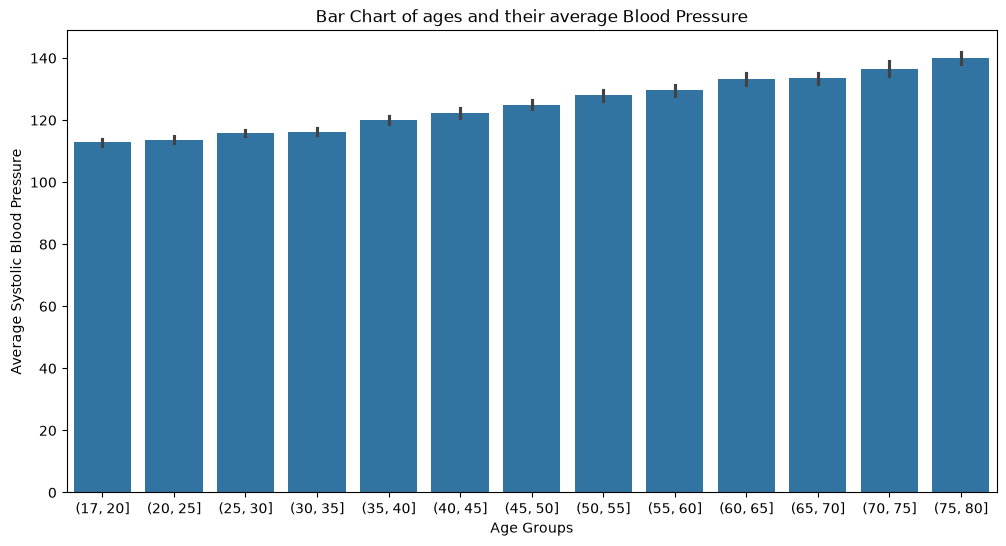

In [15]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x='AgeRanges',
    y='BPXSY1'
)
plt.title('Bar Chart of ages and their average Blood Pressure')
plt.xlabel('Age Groups')
plt.ylabel('Average Systolic Blood Pressure')
plt.show()

Let's also calculate Pearson's correlation coefficient

In [16]:
print(f'Pearsons correlation coefficient: {df['BPXSY1'].corr(df['RIDAGEYR'])})')

Pearsons correlation coefficient: 0.46923347816725725)


A Pearson correlation coefficient of 0.46 indicates a moderate positive linear relationship between Blood Pressure and Age.

Overall, we can clearly conclude the answer to our original research question. That on average, with the rise of the participant's age, the systomic blood pressure rises too.